# Повтор расчёта общего индекса качества воздуха (ОИКВ) и построение таблицы распределения ИКВ по классам для каждой станции
Код написан на основе работы «Расчет индекса качества воздуха и оценка его информативности для российских условий по данным мониторинга в Москве» И. Н. Кузнецова, Ю. В. Ткачева, И. Ю. Шалыгина, Е. А. Лезина: https://elibrary.ru/download/elibrary_46708413_18595101.pdf.

ИКВ считается из 2 таблицы (ЕС).

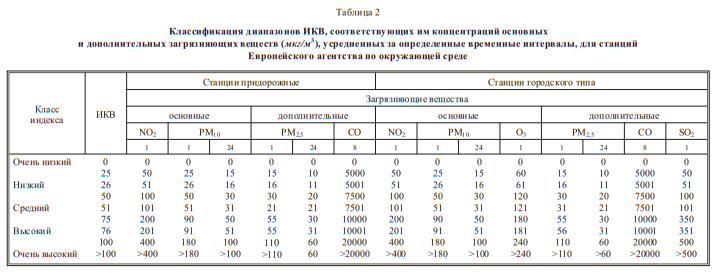

In [ ]:
# Станции городского типа
# Основные
intervals_NO2_hourly = [
    (0, 50.999, 0, 25),
    (51, 100.999, 26, 50),
    (101, 200.999, 51, 75),
    (201, 400.999, 76, 100),
    (401, float('inf'), 100, float('inf'))
]

intervals_PM10_hourly = [
    (0, 25.999, 0, 25),
    (26, 50.999, 26, 50),
    (51, 90.999, 51, 75),
    (91, 180.999, 76, 100),
    (181, float('inf'), 100, float('inf'))
]

intervals_PM10_daily = [
    (0, 15.999, 0, 25),
    (16, 30.999, 26, 50),
    (31, 50.999, 51, 75),
    (51, 100.999, 76, 100),
    (101, float('inf'), 100, float('inf'))
]

intervals_O3_hourly = [
    (0, 60.999, 0, 25),
    (61, 120.999, 26, 50),
    (121, 180.999, 51, 75),
    (181, 240.999, 76, 100),
    (241, float('inf'), 100, float('inf'))
]

# Дополнительные
intervals_PM25_hourly = [
    (0, 15.999, 0, 25),
    (16, 30.999, 26, 50),
    (31, 55.999, 51, 75),
    (56, 110.999, 76, 100),
    (111, float('inf'), 100, float('inf'))
]

intervals_PM25_daily = [
    (0, 10.999, 0, 25),
    (11, 20.999, 26, 50),
    (21, 30.999, 51, 75),
    (31, 60.999, 76, 100),
    (61, float('inf'), 100, float('inf'))
]

intervals_CO_8h = [
    (0, 5000.999, 0, 25),
    (5001, 7500.999, 26, 50),
    (7501, 10000.999, 51, 75),
    (10001, 20000.999, 76, 100),
    (20001, float('inf'), 100, float('inf'))
]

intervals_SO2_hourly = [
    (0, 50.999, 0, 25),
    (51, 100.999, 26, 50),
    (101, 350.999, 51, 75),
    (351, 500.999, 76, 100),
    (501, float('inf'), 100, float('inf'))
]

def calc_ikv(conc, intervals):
    for c_min, c_max, ikv_min, ikv_max in intervals:
        if c_min <= conc <= c_max:
            return round(ikv_min + (conc - c_min) * (ikv_max - ikv_min) / (c_max - c_min), 2)
    return None

# Станции городского типа
# Основные
def calc_ikv_NO2_hourly(conc):
    return calc_ikv(conc, intervals_NO2_hourly)

def calc_ikv_PM10_hourly(conc):
    return calc_ikv(conc, intervals_PM10_hourly)

def calc_ikv_PM10_daily(conc):
    return calc_ikv(conc, intervals_PM10_daily)

def calc_ikv_O3_hourly(conc):
    return calc_ikv(conc, intervals_O3_hourly)

# Дополнительные
def calc_ikv_PM2_5_hourly(conc):
    return calc_ikv(conc, intervals_PM25_hourly)

def calc_ikv_PM2_5_daily(conc):
    return calc_ikv(conc, intervals_PM25_daily)

def calc_ikv_CO_8_hourly(conc):
    return calc_ikv(conc, intervals_CO_8h)

def calc_ikv_SO2_hourly(conc):
    return calc_ikv(conc, intervals_SO2_hourly)

### Нахождение индекса качества воздуха (ИКВ) и построение таблицы Повторяемость (%) почасовых ИКВ по алгоритму ЕС (ИКВ-ЕС)

In [18]:
import pandas as pd

# Список файлов
filenames = [
    "st_01", "st_02", "st_05", "st_07", "st_09",
    "st_26", "st_27", "tr_03", "tr_04", "tr_05", "tr_06"
]

# Таблица для итогов по всем станциям
ikv_summary = {}

def classify_ikv_es(value):
    if value < 20:
        return "Очень низкий"
    elif value < 40:
        return "Низкий"
    elif value < 60:
        return "Средний"
    elif value < 80:
        return "Высокий"
    else:
        return "Очень высокий"

for name in filenames:
    file = name + ".csv"
    print(f"\n=== Обработка файла: {file} ===")
    
    df = pd.read_csv(file, encoding="cp1251", sep=";")
    
    df["Время"] = pd.to_datetime(df["Время"], dayfirst=True, errors='coerce')
    df = df.dropna(subset=["Время"])
    df = df.set_index("Время")

    df_hourly = df.resample("1H").mean().round(3)
    df_8_hourly = df.resample("8H").mean().round(3)
    df_daily = df.resample("1D").mean().round(3)

    df.reset_index(inplace=True)
    df_hourly.reset_index(inplace=True)
    df_8_hourly.reset_index(inplace=True)
    df_daily.reset_index(inplace=True)

    # Почасовые ИКВ
    if "Диоксид азота" in df_hourly.columns:
        df_hourly["ИКВ Диоксид азота"] = (df_hourly["Диоксид азота"] * 1000).apply(calc_ikv_NO2_hourly)

    if "Озон" in df_hourly.columns:
        df_hourly["ИКВ Озон почасовой"] = (df_hourly["Озон"] * 1000).apply(calc_ikv_O3_hourly)

    if "Частицы 10 мкм" in df_hourly.columns:
        df_hourly["ИКВ Частицы 10 мкм"] = df_hourly["Частицы 10 мкм"].apply(calc_ikv_PM10_hourly)

    if "Частицы 2.5 мкм" in df_hourly.columns:
        df_hourly["ИКВ Частицы 2.5 мкм"] = df_hourly["Частицы 2.5 мкм"].apply(calc_ikv_PM2_5_hourly)

    if "Диоксид серы" in df_hourly.columns:
        df_hourly["ИКВ Диоксид серы"] = (df_hourly["Диоксид серы"] * 1000).apply(calc_ikv_SO2_hourly)

    # 8-часовые ИКВ
    if "Оксид углерода" in df_8_hourly.columns:
        df_8_hourly["ИКВ Оксид углерода"] = df_8_hourly["Оксид углерода"].apply(calc_ikv_CO_8_hourly)

    # Суточные ИКВ
    if "Частицы 10 мкм" in df_daily.columns:
        df_daily["ИКВ Частицы 10 мкм"] = df_daily["Частицы 10 мкм"].apply(calc_ikv_PM10_daily)

    if "Частицы 2.5 мкм" in df_daily.columns:
        df_daily["ИКВ Частицы 2.5 мкм"] = df_daily["Частицы 2.5 мкм"].apply(calc_ikv_PM2_5_daily)

    # Для почасовых данных
    max_ikv_SO2 = df_hourly["ИКВ Диоксид серы"].max() if "ИКВ Диоксид серы" in df_hourly.columns else None
    max_ikv_NO2 = df_hourly["ИКВ Диоксид азота"].max() if "ИКВ Диоксид азота" in df_hourly.columns else None
    max_ikv_O3_hourly = df_hourly["ИКВ Озон почасовой"].max() if "ИКВ Озон почасовой" in df_hourly.columns else None
    max_ikv_PM10_hourly = df_hourly["ИКВ Частицы 10 мкм"].max() if "ИКВ Частицы 10 мкм" in df_hourly.columns else None
    max_ikv_PM2_5_hourly = df_hourly["ИКВ Частицы 2.5 мкм"].max() if "ИКВ Частицы 2.5 мкм" in df_hourly.columns else None

    # Для 8-часовых данных
    max_ikv_CO_8h = df_8_hourly["ИКВ Оксид углерода"].max() if "ИКВ Оксид углерода" in df_8_hourly.columns else None

    # Для суточных данных
    max_ikv_PM10_daily = df_daily["ИКВ Частицы 10 мкм"].max() if "ИКВ Частицы 10 мкм" in df_daily.columns else None
    max_ikv_PM2_5_daily = df_daily["ИКВ Частицы 2.5 мкм"].max() if "ИКВ Частицы 2.5 мкм" in df_daily.columns else None

    # Печать результатов
    print("Максимальный ИКВ Диоксид серы (почасовой):", max_ikv_SO2)
    print("Максимальный ИКВ Диоксид азота (почасовой):", max_ikv_NO2)
    print("Максимальный ИКВ Озон (почасовой):", max_ikv_O3_hourly)
    print("Максимальный ИКВ Частицы 10 мкм (почасовой):", max_ikv_PM10_hourly)
    print("Максимальный ИКВ Частицы 2.5 мкм (почасовой):", max_ikv_PM2_5_hourly)
    print("Максимальный ИКВ Оксид углерода (8-часовой):", max_ikv_CO_8h)
    print("Максимальный ИКВ Частицы 10 мкм (суточный):", max_ikv_PM10_daily)
    print("Максимальный ИКВ Частицы 2.5 мкм (суточный):", max_ikv_PM2_5_daily)
    
    # Определение общего максимального ИКВ
    valid_ikv = {k: v for k, v in {
        "ИКВ Диоксид серы (почасовой)": max_ikv_SO2,
        "ИКВ Диоксид азота (почасовой)": max_ikv_NO2,
        "ИКВ Озон (почасовой)": max_ikv_O3_hourly,
        "ИКВ Частицы 10 мкм (почасовой)": max_ikv_PM10_hourly,
        "ИКВ Частицы 2.5 мкм (почасовой)": max_ikv_PM2_5_hourly,
        "ИКВ Оксид углерода (8-часовой)": max_ikv_CO_8h,
        "ИКВ Частицы 10 мкм (суточный)": max_ikv_PM10_daily,
        "ИКВ Частицы 2.5 мкм (суточный)": max_ikv_PM2_5_daily
    }.items() if v is not None}

    if valid_ikv:
        max_name, max_value = max(valid_ikv.items(), key=lambda x: x[1])
        print(">>> Общий максимум ИКВ:", max_value)
        print(">>> Показатель:", max_name)
    else:
        print(">>> Нет доступных значений ИКВ для вычисления общего максимума.")
    
    # Выбираем только числовые столбцы с ИКВ
    ikv_columns = [
        col for col in df_hourly.columns
        if col.startswith("ИКВ") and pd.api.types.is_numeric_dtype(df_hourly[col])
    ]

    # Добавляем максимальный ИКВ и соответствующий показатель
    if ikv_columns:
        df_hourly["ИКВ общий"] = df_hourly[ikv_columns].max(axis=1)

    def get_max_column(row):
        ikv_vals = row[ikv_columns].astype(float)
        return ikv_vals.idxmax() if not ikv_vals.isna().all() else None


    df_hourly["ИКВ показатель"] = df_hourly.apply(get_max_column, axis=1)
    
    # Удаляем строки с отсутствующим ИКВ
    df_hourly_valid = df_hourly.dropna(subset=["ИКВ общий"]).copy()

    # Классификация по ЕС
    df_hourly_valid["ИКВ-ЕС"] = df_hourly_valid["ИКВ общий"].apply(classify_ikv_es)

    # Подсчет долей в процентах
    es_counts = df_hourly_valid["ИКВ-ЕС"].value_counts(normalize=True) * 100

    ikv_summary[name] = {
        "ЕС": es_counts.to_dict()
    }

# Подготовка финальной таблицы
columns_order = ["Очень низкий", "Низкий", "Средний", "Высокий", "Очень высокий"]
summary_df = pd.DataFrame(columns=["Станция", "Класс ИКВ", *columns_order])

for station, data in ikv_summary.items():
    row_es = [station, "ИКВ-ЕС"]
    for cls in columns_order:
        row_es.append(round(data["ЕС"].get(cls, 0), 1))
    summary_df.loc[len(summary_df)] = row_es

# Печать таблицы
print("\nТаблица распределения ИКВ по классам (в %):\n")
print(summary_df.to_string(index=False))


=== Обработка файла: st_01.csv ===
Максимальный ИКВ Диоксид серы (почасовой): 53.69
Максимальный ИКВ Диоксид азота (почасовой): 83.92
Максимальный ИКВ Озон (почасовой): None
Максимальный ИКВ Частицы 10 мкм (почасовой): 0.39
Максимальный ИКВ Частицы 2.5 мкм (почасовой): 0.49
Максимальный ИКВ Оксид углерода (8-часовой): 0.02
Максимальный ИКВ Частицы 10 мкм (суточный): 0.23
Максимальный ИКВ Частицы 2.5 мкм (суточный): 0.31
>>> Общий максимум ИКВ: 83.92
>>> Показатель: ИКВ Диоксид азота (почасовой)

=== Обработка файла: st_02.csv ===
Максимальный ИКВ Диоксид серы (почасовой): 79.68
Максимальный ИКВ Диоксид азота (почасовой): 80.44
Максимальный ИКВ Озон (почасовой): None
Максимальный ИКВ Частицы 10 мкм (почасовой): 1.82
Максимальный ИКВ Частицы 2.5 мкм (почасовой): 2.87
Максимальный ИКВ Оксид углерода (8-часовой): 0.03
Максимальный ИКВ Частицы 10 мкм (суточный): 0.49
Максимальный ИКВ Частицы 2.5 мкм (суточный): 0.7
>>> Общий максимум ИКВ: 80.44
>>> Показатель: ИКВ Диоксид азота (почасовой)